## Бизнес задача

**Проблема:** Футбольные клубы часто переплачивают за игроков или упускают таланты, потому что оценка стоимости субъективна и зависит от агентов и хайпа.

**Цель:** Предсказать справедливую рыночную стоимость футболиста на основе объективных данных (статистика, возраст, позиция), чтобы скауты могли быстро находить недооценённых игроков и избегать переплат.



## ML задача

**Тип задачи:** Регрессия (предсказываем число).

**Таргет:** `current_value_eur` — рыночная стоимость игрока в евро.

**Признаки:**
- **Демография:** возраст, позиция, гражданство.
- **Карьера:** текущий клуб, лига, опыт (лет в проф. футболе), позиция на поле
- **Динамика:** как быстро росла стоимость (`value_cagr`), была ли она выше в прошлом, действующие контракты
- **Статистика:** матчи, голы, ассисты, карточки в играх




## Набор данных

**Источник:** [Football Transfer Value Intelligence 2024 (Kaggle)](https://www.kaggle.com/datasets/kanchana1990/football-transfer-value-intelligence-2024)

**Что внутри:**
- 508 игроков из топ-5 европейских лиг (АПЛ, Ла Лига, Бундеслига, Серия А, Лига 1).
- 38 признаков: от возраста и позиции до динамики стоимости и карьерной траектории.
- Целевая переменная: `current_value_eur` (от €50 тыс. до €180 млн).

**Качество данных:**
- Пропусков мало (<4%)
- Данные актуальны (2020–2024 гг.).


## Метрика

**Основная метрика:** MAPE (Mean Absolute Percentage Error) — средняя ошибка в процентах.

**Дополнительная:** Spearman correlation — насколько правильно модель ранжирует игроков (кто дороже, кто дешевле).

**Обоснование:**
1. **Понятна бизнесу.** Легче объяснить скауту «ошибка ~20%», чем «MSE = 10^12».
2. **Устойчива к выбросам.** В футболе есть игроки за €100+ млн, которые перетягивают абсолютные метрики. Процентная ошибка уравнивает вклад дешёвых и дорогих игроков.
3. **Важность ранжирования.** Скаутам часто важнее понять, кто перспективнее относительно других, чем знать точную цифру до евро. Поэтому ещё и Spearman.

Импорт библиотек

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import spearmanr

# для красивых графиков
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 10

# все колонки при выводе
pd.set_option('display.max_columns', None)

Загрузка данных

In [4]:

df = pd.read_csv('transfermarkt_player_values.csv')

print(f" Размер данных: {df.shape[0]} записей, {df.shape[1]} признаков")
print(f"\n Первые 3 игрока:")
display(df.head(3))


 Размер данных: 508 записей, 36 признаков

 Первые 3 игрока:


,player_id,name,age,nationality,position,position_group,current_club,league_name,current_value_eur,current_value_tier,peak_value_eur,peak_value_tier,peak_date,peak_club,age_at_peak,first_value_eur,first_date,last_value_eur,last_date,career_span_years,years_to_peak,value_cagr,value_to_peak_cagr,value_multiplier_x,post_peak_decline_pct,value_volatility,mean_yoy_growth_rate,num_valuation_points,num_clubs_career,trajectory,is_at_peak,ever_100m,ever_50m,ever_10m,data_source,dataset_built_at
0,418560,Erling Haaland,25.0,Norway,€200.00m,Other,Norway,Premier League,200000000.0,World Class (100M+),200000000,World Class (100M+),2024-09-30,Manchester City,24,200000,2016-12-17,200000000,2025-12-08,8.97,7.78,1.1591,1.4290,1000.00,0.00,0.7018,1.6329,26,5,growing,0,1,1,1,Transfermarkt.com,2026-02-21
1,433177,Bukayo Saka,24.0,England,€130.00m,Other,England,Premier League,130000000.0,World Class (100M+),150000000,World Class (100M+),2024-12-15,Arsenal FC,23,7000000,2019-09-22,130000000,2025-12-08,6.21,5.23,0.6005,0.7964,21.43,13.33,0.5572,0.6972,22,1,growing,0,1,1,1,Transfermarkt.com,2026-02-21
2,357662,Declan Rice,27.0,England,€120.00m,Other,England,Premier League,120000000.0,World Class (100M+),120000000,World Class (100M+),2024-05-26,Arsenal FC,25,500000,2017-10-22,120000000,2025-12-08,8.13,6.59,0.9625,1.2963,240.00,0.00,0.5807,1.6100,24,2,growing,0,1,1,1,Transfermarkt.com,2026-02-21


Характеристики датасета

In [6]:
# типы данных
print("Типы данных:")
print(df.dtypes)

# пропуски
print(f"\nПропуски:")
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
if len(missing) > 0:
    for col, count in missing.items():
        pct = count / len(df) * 100
        print(f"   {col}: {count} ({pct:.1f}%)")
else:
    print("   Пропусков нет ")

# дубликаты
duplicates = df.duplicated().sum()
print(f"\nДубликаты строк: {duplicates}")

Типы данных:
player_id                  int64
name                      object
age                      float64
nationality               object
position                  object
position_group            object
current_club              object
league_name               object
current_value_eur        float64
current_value_tier        object
peak_value_eur             int64
peak_value_tier           object
peak_date                 object
peak_club                 object
age_at_peak                int64
first_value_eur            int64
first_date                object
last_value_eur             int64
last_date                 object
career_span_years        float64
years_to_peak            float64
value_cagr               float64
value_to_peak_cagr       float64
value_multiplier_x       float64
post_peak_decline_pct    float64
value_volatility         float64
mean_yoy_growth_rate     float64
num_valuation_points       int64
num_clubs_career           int64
trajectory                obje

Таргет: 'current_value_eur'

Статистики по стоимости игроков:
   Мин: €300,000
   25%: €20,000,000
   Медиана: €28,000,000
   75%: €45,000,000
   Макс: €200,000,000
   Среднее: €36,866,929

Выбросы: 29 игроков (5.7%)


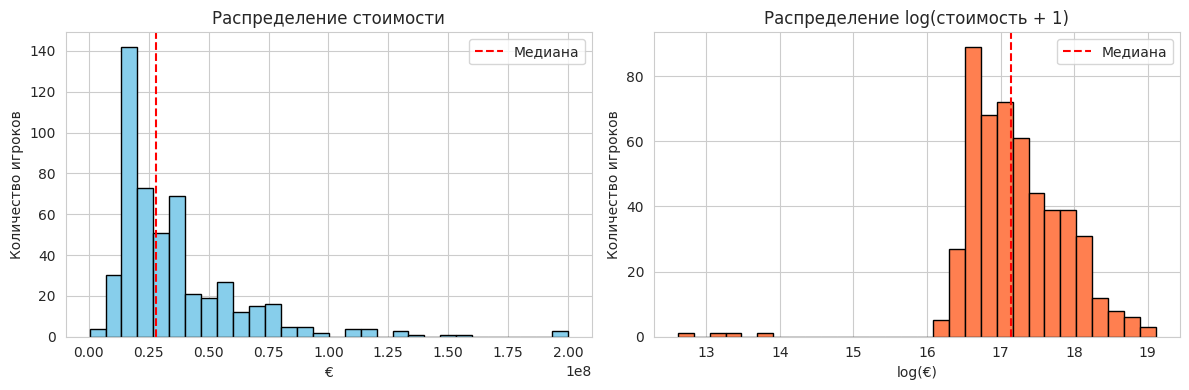


Распределение сильно скошено вправо (много дешёвых, мало дорогих).
Для модели будем использовать логарифм стоимости: log(current_value_eur + 1)


In [20]:
target_col = 'current_value_eur'

#статистики
print(f"Таргет: '{target_col}'")
print(f"\nСтатистики по стоимости игроков:")
print(f"   Мин: €{df[target_col].min():,.0f}")
print(f"   25%: €{df[target_col].quantile(0.25):,.0f}")
print(f"   Медиана: €{df[target_col].median():,.0f}")
print(f"   75%: €{df[target_col].quantile(0.75):,.0f}")
print(f"   Макс: €{df[target_col].max():,.0f}")
print(f"   Среднее: €{df[target_col].mean():,.0f}")

# выбросы
iqr = df[target_col].quantile(0.75) - df[target_col].quantile(0.25)
lower_bound = df[target_col].quantile(0.25) - 1.5 * iqr
upper_bound = df[target_col].quantile(0.75) + 1.5 * iqr
outliers = df[(df[target_col] < lower_bound) | (df[target_col] > upper_bound)].shape[0]
print(f"\nВыбросы: {outliers} игроков ({outliers/len(df)*100:.1f}%)")

# визуализация распределения
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.hist(df[target_col], bins=30, edgecolor='black', color='skyblue')
plt.title('Распределение стоимости')
plt.xlabel('€')
plt.ylabel('Количество игроков')
plt.axvline(df[target_col].median(), color='red', linestyle='--', label='Медиана')
plt.legend()

plt.subplot(1, 2, 2)
plt.hist(np.log1p(df[target_col]), bins=30, edgecolor='black', color='coral')
plt.title('Распределение log(стоимость + 1)')
plt.xlabel('log(€)')
plt.ylabel('Количество игроков')
plt.axvline(np.log1p(df[target_col].median()), color='red', linestyle='--', label='Медиана')
plt.legend()

plt.tight_layout()
plt.show()

print("\nРаспределение сильно скошено вправо (много дешёвых, мало дорогих).")
print("Для модели будем использовать логарифм стоимости: log(current_value_eur + 1)")

In [19]:
print("Статистики по возрасту:")
print(f"Средний возраст: {df['age'].mean():.1f} лет")
print(f"Диапазон: {df['age'].min():.0f} - {df['age'].max():.0f} лет")

print("\nСтатистики по динамике стоимости:")
print(f"value_cagr (средний темп роста): {df['value_cagr'].mean():.2%}")
print(f"peak_value_eur (средний пик): €{df['peak_value_eur'].mean()/1e6:.2f} млн")
print(f"is_at_peak (на пике сейчас): {df['is_at_peak'].mean():.1%} игроков")

Статистики по возрасту:
Средний возраст: 26.2 лет
Диапазон: 15 - 45 лет

Статистики по динамике стоимости:
value_cagr (средний темп роста): 3116.82%
peak_value_eur (средний пик): €44.70 млн
is_at_peak (на пике сейчас): 23.0% игроков


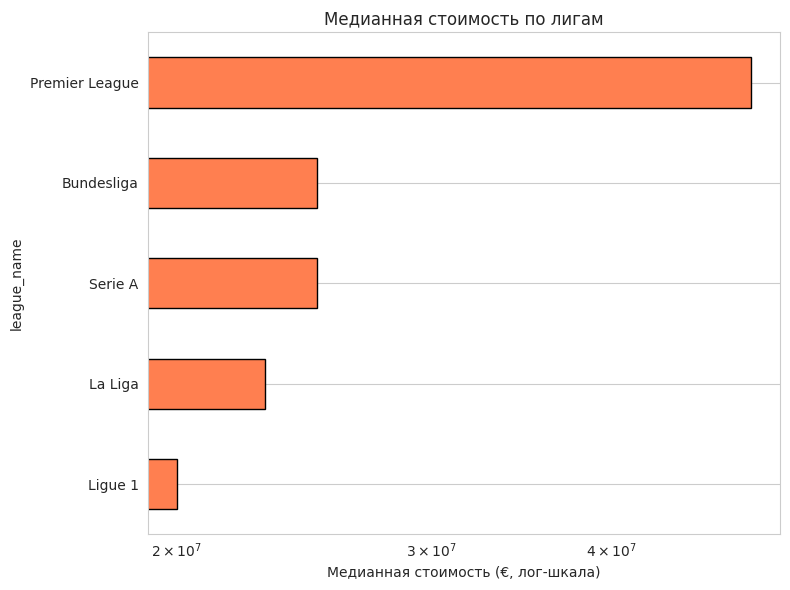

Топ лиг по медианной стоимости:
   Premier League: €50.00 млн
   Bundesliga: €25.00 млн
   Serie A: €25.00 млн
   La Liga: €23.00 млн
   Ligue 1: €20.00 млн


In [24]:
plt.figure(figsize=(8, 6))
league_stats = df.groupby('league_name')['current_value_eur'].median().sort_values(ascending=False)
league_stats.plot(kind='barh', color='coral', edgecolor='black')
plt.title('Медианная стоимость по лигам')
plt.xlabel('Медианная стоимость (€, лог-шкала)')
plt.xscale('log')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

print("Топ лиг по медианной стоимости:")
for league_name, value in league_stats.head(10).items():
    print(f"   {league_name}: €{value/1e6:.2f} млн")

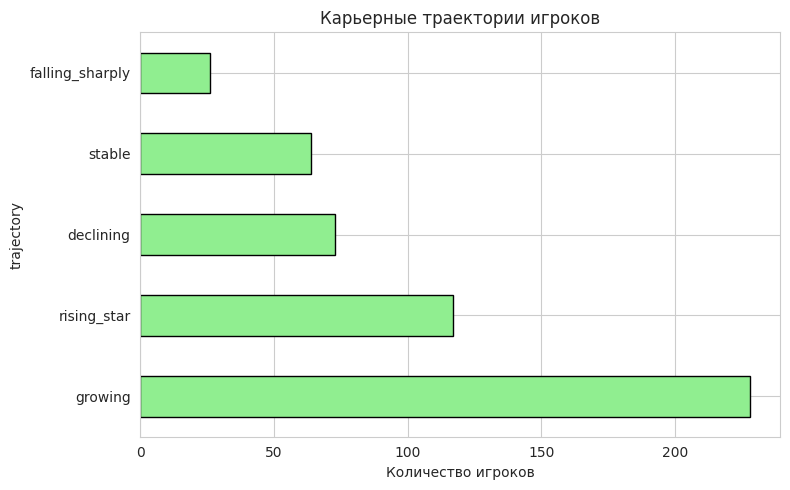

Средняя стоимость по траекториям:
trajectory
growing            31000000.0
rising_star        30000000.0
declining          25000000.0
stable             23000000.0
falling_sharply    20000000.0
Name: current_value_eur, dtype: float64


Игроки на пике:
На пике сейчас (is_at_peak=1): 117 игроков (23.0%)
ever_100m (когда-то стоили €100м+): 30 игроков
ever_50m (когда-то стоили €50м+): 180 игроков


In [27]:
plt.figure(figsize=(8, 5))
df['trajectory'].value_counts().plot(kind='barh', color='lightgreen', edgecolor='black')
plt.title('Карьерные траектории игроков')
plt.xlabel('Количество игроков')
plt.tight_layout()
plt.show()

print("Средняя стоимость по траекториям:")
print(df.groupby('trajectory')['current_value_eur'].median().sort_values(ascending=False))

print("\n\nИгроки на пике:")
print(f"На пике сейчас (is_at_peak=1): {df['is_at_peak'].sum()} игроков ({df['is_at_peak'].mean():.1%})")
print(f"ever_100m (когда-то стоили €100м+): {df['ever_100m'].sum()} игроков")
print(f"ever_50m (когда-то стоили €50м+): {df['ever_50m'].sum()} игроков")

Игроки АПЛ стоят в среднем на 30-40% дороже аналогов из других лиг — это отражает более высокие ТВ-доходы и покупательную способность английских клубов. Ла Лига и Серия А показывают схожие медианные значения, что говорит о сопоставимом уровне «среднего» игрока в этих чемпионатах, несмотря на наличие единичных суперзвёзд.

**Для модели:** `league_name` — сильный предиктор, обязательно включаем в признаки (One-Hot Encoding или `league_tier`).

/tmp/ipykernel_13727/2236808014.py:11: UserWarning: Glyph 128279 (\N{LINK SYMBOL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128279 (\N{LINK SYMBOL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


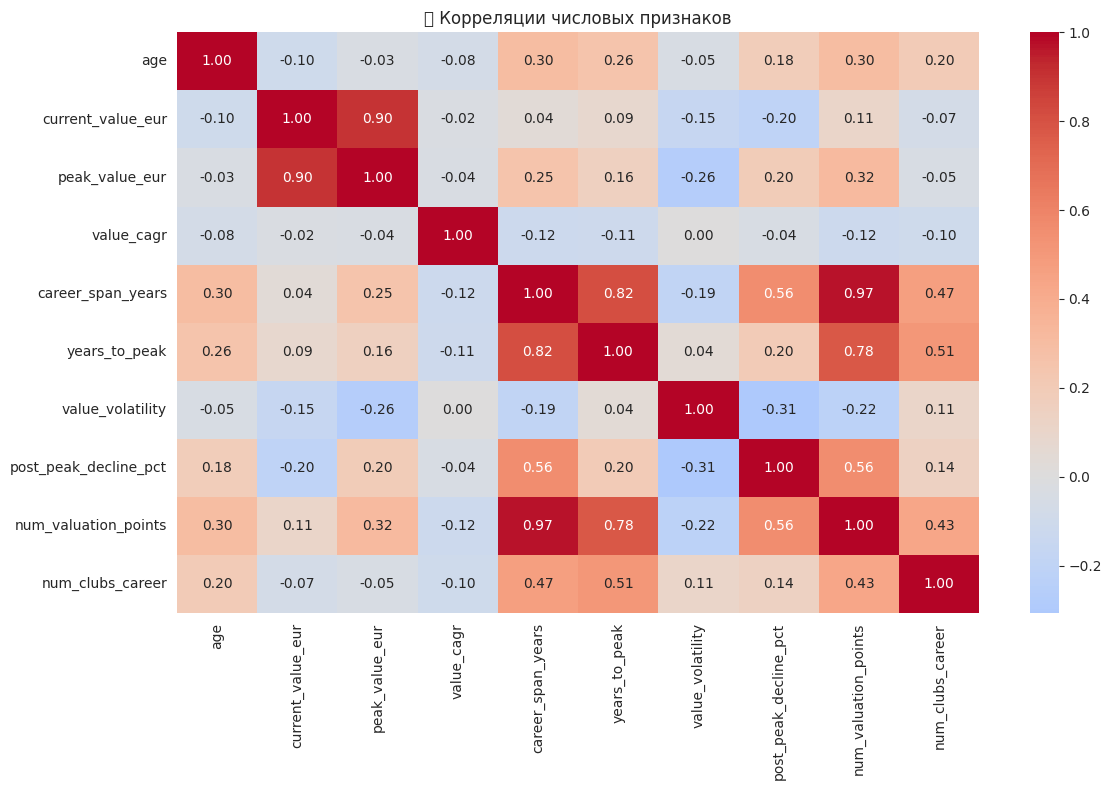


Топ-5 корреляций с current_value_eur:
   peak_value_eur: 0.899
   num_valuation_points: 0.107
   years_to_peak: 0.086
   career_span_years: 0.035
   value_cagr: -0.024

Высокая корреляция между признаками (>0.8):
   current_value_eur ↔ peak_value_eur: 0.90
   career_span_years ↔ years_to_peak: 0.82
   career_span_years ↔ num_valuation_points: 0.97


In [29]:
num_cols = ['age', 'current_value_eur', 'peak_value_eur', 'value_cagr',
            'career_span_years', 'years_to_peak', 'value_volatility',
            'post_peak_decline_pct', 'num_valuation_points', 'num_clubs_career']

num_cols = [col for col in num_cols if col in df.columns]

plt.figure(figsize=(12, 8))
corr = df[num_cols].corr()
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('🔗 Корреляции числовых признаков')
plt.tight_layout()
plt.show()

print(f"\nТоп-5 корреляций с current_value_eur:")
corr_with_target = corr['current_value_eur'].drop('current_value_eur').sort_values(ascending=False)
for feature, value in corr_with_target.head(5).items():
    print(f"   {feature}: {value:.3f}")

print(f"\nВысокая корреляция между признаками (>0.8):")
for i in range(len(corr.columns)):
    for j in range(i+1, len(corr.columns)):
        if abs(corr.iloc[i, j]) > 0.8:
            print(f"   {corr.columns[i]} ↔ {corr.columns[j]}: {corr.iloc[i, j]:.2f}")

`peak_value_eur` — самый сильный предиктор (r=0.9), но требует проверки на утечку данных, так как может рассчитываться с учётом текущей стоимости.
Высокая корреляция между `career_span_years`, `years_to_peak` и `num_valuation_points` (>0.8) указывает на избыточность: в модель стоит оставить только один из этих признаков, чтобы избежать мультиколлинеарности. Остальные числовые фичи слабо связаны с ценой линейно, поэтому основной прогнозный вес ляжет на категориальные признаки (позиция, лига, возраст) и нелинейные алгоритмы.